In [1]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
from sklearn.metrics.cluster import adjusted_rand_score as ARI
from tqdm.auto import tqdm
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW
from vem_sbm_new_version_VICL import VEM_SBM as VEM_SBM_NEW_vicl

from tqdm.auto import tqdm
from ILouvain_Gower import ML2Gower
from sklearn.metrics.cluster import adjusted_rand_score as ARI
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from stoc import stoc
import pickle

col_dict = {0: 'red', 1: 'blue', 2: 'green', 3: 'orange', 4:'purple', 5:'black', 6:'yellow', 7:'pink', 8:'lightblue',9:'lime', 10:'sienna',11:'indigo'}

# Rete quasi bipartita

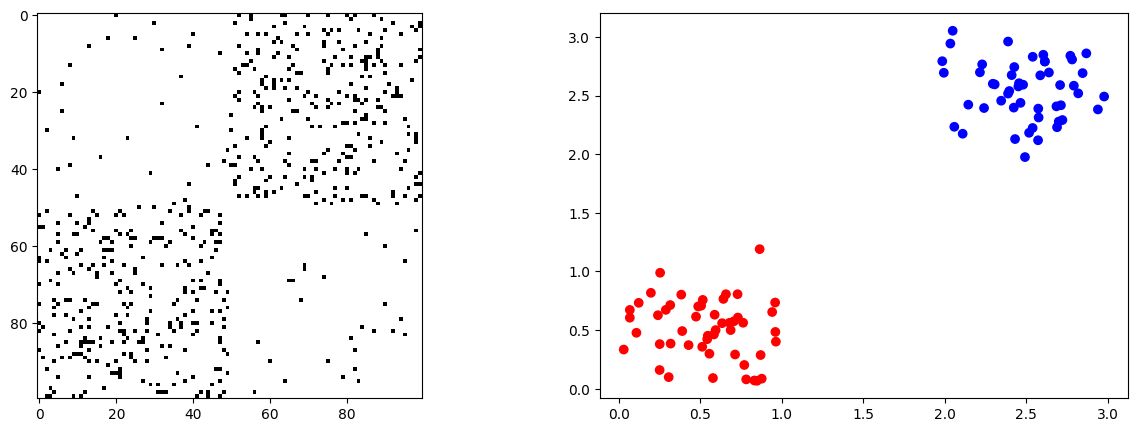

In [2]:
random.seed(42)
size_comm = [50,50]
probs = [[0.01, 0.1],[0.1,0.01]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((100,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=50)
#Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.08, 0.003], [0.003, 0.08]], size=50)

Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

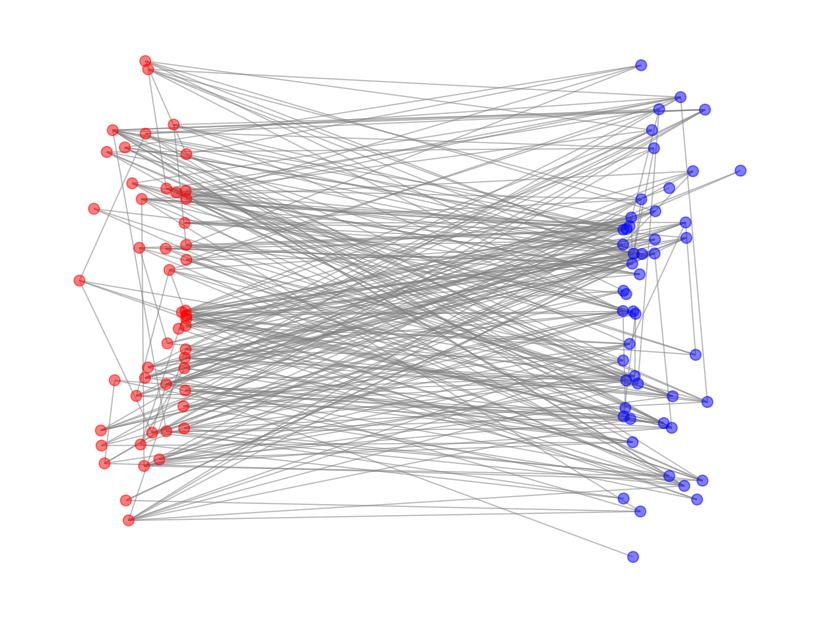

In [54]:
block0_nodes = [n for n in G.nodes() if labels[n] == 0]
init_pos = nx.bipartite_layout(G, block0_nodes)

pos = nx.spring_layout(G, pos=init_pos, iterations=6, seed=42)

plt.figure(figsize=(8, 6))
nx.draw(G, pos,node_size=60,edge_color="gray",alpha=0.5,with_labels=False, node_color=dtemp['label'])
plt.show()

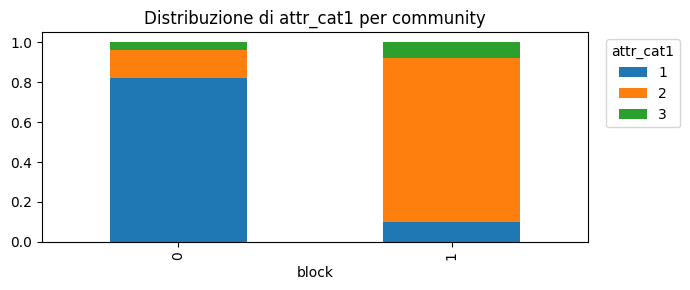

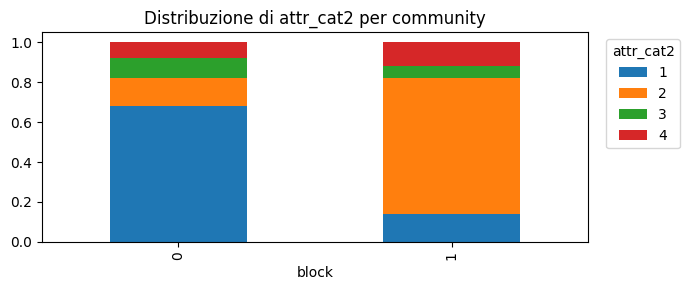

In [4]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
#Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
#Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

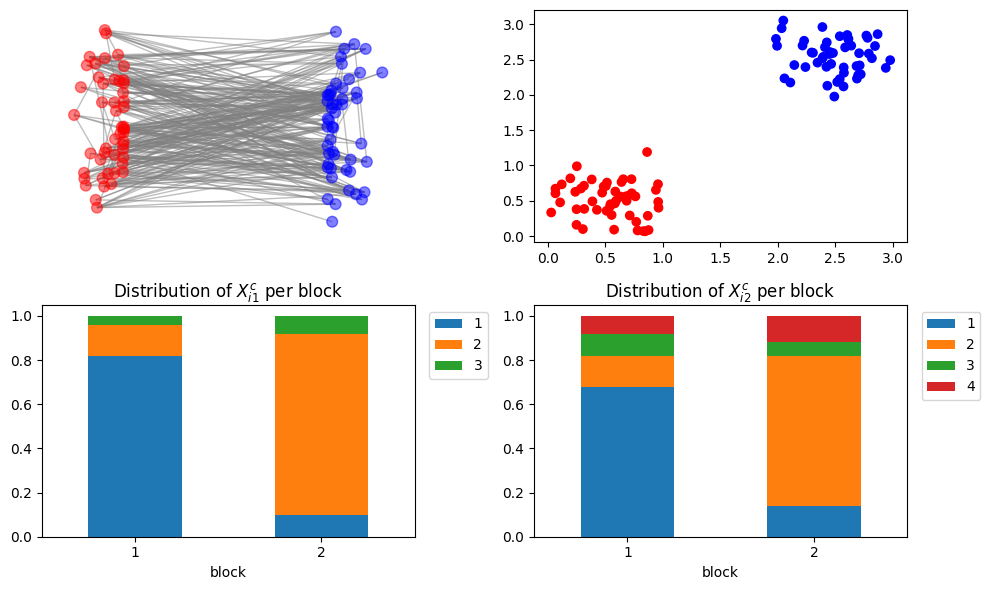

In [56]:
df = Xc.copy()
df["block"] = labels

fig, axes = plt.subplots(2,2,figsize=(10,6))
nx.draw(G, pos,node_size=60,edge_color="gray",alpha=0.5,with_labels=False, ax=axes[0,0], node_color=dtemp['label'])
#nx.draw(G, pos=nx.spring_layout(G, k=0.6,seed=6), ax=axes[0,0], node_size=10, width=0.1, node_color=dtemp['label'])
axes[0,1].scatter(dtemp.loc[:, 0], dtemp.loc[:, 1], c=dtemp['label'])

titles = [rf"$X_{{i1}}^c$", rf"$X_{{i2}}^c$"]
for i, col in enumerate(["attr_cat1", "attr_cat2"]):
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=axes[1,i])
    axes[1,i].set_title(f"Distribution of {titles[i]} per block")
    axes[1,i].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    axes[1,i].set_xticklabels([1,2], rotation=0)

plt.tight_layout()
plt.savefig('plot_fourth_2x2.png')
plt.show()

In [5]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW_old
from vem_sbm_new_version_VICL import VEM_SBM as VEM_SBM_NEW_vicl


Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [6]:
[Rs[k]['vICL'] for k in Rs.keys()]

[-1277.2991391302319,
 -1309.6021408009385,
 -1339.3514264759,
 -1365.2361549436657]

In [7]:
pd.DataFrame(Rs[2]['r'])

,0,1
0,1.054279e-45,1.000000e+00
1,9.163043e-40,1.000000e+00
2,5.909300e-36,1.000000e+00
3,3.746311e-48,1.000000e+00
4,2.353287e-37,1.000000e+00
...,...,...
95,1.000000e+00,1.146220e-35
96,1.000000e+00,1.391486e-34
97,1.000000e+00,1.758676e-32
98,1.000000e+00,6.770117e-44


In [8]:
size_comm = [50,50]

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

theta_true = [[0.01, 0.1],[0.1,0.01]]
means_true = [[0.5, 0.5],[2.5, 2.5]]
sigmas_true = [[[0.08, 0.001], [0.001, 0.08]], [[0.07, 0.002], [0.002, 0.07]]]
phi1_true = [[0.8,0.15,0.05],[0.15,0.8,0.05]]
phi2_true =  [[0.7,0.15,0.05,0.1],[0.15,0.7,0.05,0.1]]

In [9]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    return col_ind

def mse(true, est):
    return np.mean((np.array(true) - np.array(est))**2)

In [35]:
with open('bipartita_fits.pkl', 'rb') as f:
   fits = pickle.load(f)

K = 2
results = {
    'ari': [],
    'theta': [],
    **{f'mu_{k}': [] for k in range(K)},
    **{f'sigma_{k}': [] for k in range(K)},
    'phi1': [],
    'phi2': [],
}

for sed in range(1):
    fit = fits[sed]
    if fit['r'].shape[1] == 2 and all(p.shape[1] == t for p, t in zip(fit['phi_list'], [3,4])):
        pred = np.argmax(fit['r'], axis=1)
        perm = match_labels(np.array(labels), pred, K)
        
        Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
        mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
        Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
        phi_aligned = [phi[perm, :] for phi in fit['phi_list']]
        
        results['ari'].append(ARI(labels, pred))
        results['theta'].append(mse(theta_true, Theta_aligned))
        results['phi1'].append(mse(phi1_true, phi_aligned[0]))
        results['phi2'].append(mse(phi2_true, phi_aligned[1]))
        
        for k in range(K):
            results[f'mu_{k}'].append(mse(means_true[k], mu_aligned[k]))
            results[f'sigma_{k}'].append(mse(sigmas_true[k], Sigma_aligned[k]))

In [14]:
pd.Series([fits[i]['r'].shape[1] for i in fits.keys()]).value_counts()

2    496
3      3
4      1
Name: count, dtype: int64

In [47]:
sbm_aris = []
for sed in range(500):
    fit = fits[sed]
    pred = np.argmax(fit['r'], axis=1)
    
    sbm_aris.append(ARI(labels, pred))
sbm_aris = np.array(sbm_aris)

In [49]:
sbm_aris.std()

0.044766620766636026

In [36]:
results

{'ari': [1.0],
 'theta': [3.5729779258642216e-06],
 'mu_0': [0.00042894893000574056],
 'mu_1': [0.001148103506663117],
 'sigma_0': [1.1121875143560203e-05],
 'sigma_1': [1.1535386881780182e-05],
 'phi1': [0.004333333333333336],
 'phi2': [0.0018999999999999974]}

In [27]:
summary = pd.DataFrame({key: {'mean': np.mean(vals), 'std': np.std(vals)} 
                         for key, vals in results.items()}).T
print(summary.round(5))

            mean      std
ari      1.00000  0.00000
theta    0.00002  0.00003
mu_0     0.00157  0.00163
mu_1     0.00141  0.00137
sigma_0  0.00018  0.00014
sigma_1  0.00014  0.00011
phi1     0.00220  0.00194
phi2     0.00232  0.00150


In [43]:
with open('bipartita_ilouv_aris.pkl', 'rb') as f:
   ilouvain_aris = pickle.load(f)

with open('bipartita_sa_aris.pkl', 'rb') as f:
   sa_aris = pickle.load(f)

with open('bipartita_stoc_aris.pkl', 'rb') as f:
   stoc_aris = pickle.load(f)

In [44]:
vals = ilouvain_aris
print(f"${np.mean(vals).round(5)} \pm {np.std(vals).round(5)}$")

$-0.01319 \pm 0.00232$


In [45]:
vals = sa_aris
print(f"${np.mean(vals).round(5)} \pm {np.std(vals).round(5)}$")

$0.04692 \pm 0.10422$


In [46]:
vals = stoc_aris
print(f"${np.mean(vals).round(5)} \pm {np.std(vals).round(5)}$")

$0.00041 \pm 0.00045$


In [32]:
fit = fits[0]
pred = np.argmax(fit['r'], axis=1)
perm = match_labels(np.array(labels), pred, K)

Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
phi_aligned = [phi[perm, :] for phi in fit['phi_list']]

In [42]:
theta_true

[[0.01, 0.1], [0.1, 0.01]]

In [33]:
Theta_aligned

array([[0.01306122, 0.1012    ],
       [0.1012    , 0.01142857]])

In [6]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

In [9]:
pred_labels_sbm

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [7]:
Rs[3]['Theta']

array([[0.50122449, 0.1016    , 0.2128    ],
       [0.1016    , 0.50530612, 0.0536    ],
       [0.2128    , 0.0536    , 0.5877551 ]])

In [ ]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    """Find the permutation of pred labels that best matches true labels."""
    # Build cost matrix: -overlap between each (true k, pred l) pair
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[k] = which predicted label corresponds to true label k
    return col_ind

perm = match_labels(np.array(labels), pred_labels_sbm, 3)
# perm[k] = estimated label that corresponds to true block k

# Reorder Theta to match true label order
Theta_est = Rs[3]['Theta']
Theta_aligned = Theta_est[np.ix_(perm, perm)]
print('True:\n', np.array(probs))
print('Estimated (aligned):\n', np.round(Theta_aligned, 3))

In [7]:
fits = {}
ilouvain_aris = []
sa_aris = []
stoc_aris = []

for sed in tqdm(range(500)):
    random.seed(sed)
    np.random.seed(sed)

    size_comm = [50,50]
    probs = [[0.01, 0.1],[0.1,0.01]]
    G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

    Xg=np.zeros((100,2))
    Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=50)
    Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=50)
    #Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.08, 0.003], [0.003, 0.08]], size=50)

    Xg=pd.DataFrame(Xg)
    A=nx.adjacency_matrix(G).todense()

    Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
    Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
    Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
    #Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

    Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
    Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])

    Ks = [2,3,4]
    Rs = {}

    for K in Ks:
        fit = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
        Rs[K] = fit
    bestK = np.array([Rs[K]['vICL'] for K in Ks]).argmax() + 2
    fits[sed] = Rs[bestK]

    # ILOUVAIN
    attributes = {}
    for node in G.nodes():
        attributes[node] = {
            0: float(Xg.iloc[node, 0]),     # continuous
            1: float(Xg.iloc[node, 1]),     # continuous
            2: str(Xc.iloc[node, 0]),       # categorical
            3: str(Xc.iloc[node, 1]),       # categorical
        }

    attr_types = {0: 'continuous', 1: 'continuous',
                2: 'categorical', 3: 'categorical'}

    ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
    partition_ilouv = ml.findPartition()
    ilouvain_aris.append(ARI(list(partition_ilouv.values()), labels))

    # SA
    result_sa = sa_cluster(G, k=bestK, Xg=Xg, Xc=Xc, n_bins=10, 
                        l=20, c=0.15, sigma=0.5, verbose=False)
    sa_aris.append(adjusted_rand_score(labels, result_sa['labels']))

    # STOC
    result_stoc = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

    stoc_aris.append(ARI(labels, result_stoc['labels']))

    with open('bipartita_fits.pkl', 'wb') as f:
        pickle.dump(fits, f)

    with open('bipartita_ilouv_aris.pkl', 'wb') as f:
        pickle.dump(ilouvain_aris, f)

    with open('bipartita_sa_aris.pkl', 'wb') as f:
        pickle.dump(sa_aris, f)

    with open('bipartita_stoc_aris.pkl', 'wb') as f:
        pickle.dump(stoc_aris, f)

  0%|          | 0/500 [00:00<?, ?it/s]

/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:86: RuntimeWarning: overflow encountered in matmul
  qf = float((diff.T @ Sinv @ diff)[0, 0])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:176: RuntimeWarning: invalid value encountered in scalar multiply
  term_g += r[i, k] * log_mvnorm(Xg[i, :], mu_list[k], Sigma_list[k])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:86: RuntimeWarning: invalid value encountered in matmul
  qf = float((diff.T @ Sinv @ diff)[0, 0])


In [15]:
pd.Series([fits[i]['r'].shape[1] for i in fits.keys()]).value_counts()

2    496
3      3
4      1
Name: count, dtype: int64

### ILouvain

In [43]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [46]:
ARI(list(partition_ilouv.values()), labels)

-0.01320487273773085

### SA cluster third

In [48]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0035


### STOC cluster third

In [49]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.3066
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 100 clusters
k=99  ARI=0.0004


# Core periphery

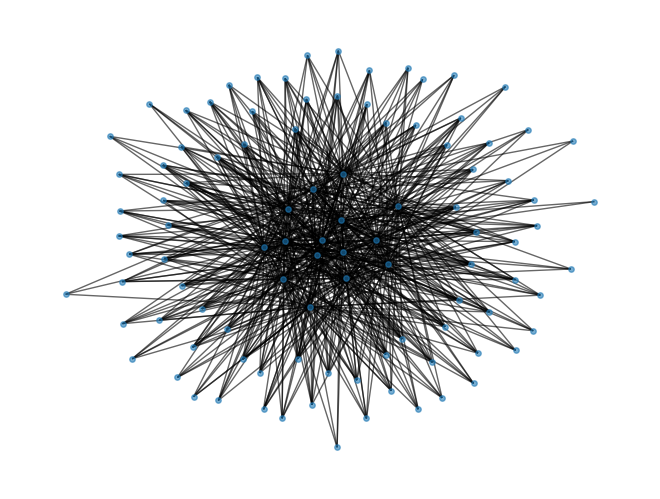

In [2]:
N = 100
A_c = np.zeros((100,100))
for i in range(15):
    x = random.choices([0,1], k=100, weights=[0.5,0.5])
    A_c[i,:] = x
    A_c[:,i] = x
np.fill_diagonal(A_c,0)

G = nx.from_numpy_array(A_c)
nx.draw_kamada_kawai(G,node_size=15,linewidths=1,alpha=0.6)

In [21]:
random.seed(42)
size_comm = [30,70]
probs = [[0.5, 0.5],[0.5,0.02]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)
A=nx.adjacency_matrix(G).todense()

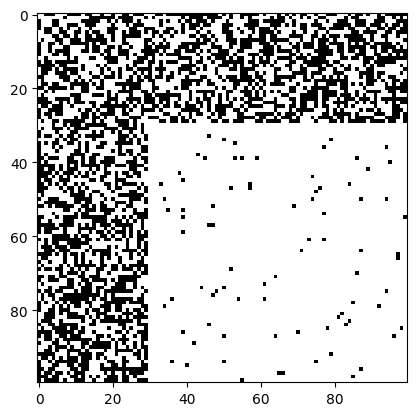

In [22]:
Xg=np.zeros((100,2))
Xg[:30,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=30)
Xg[30:,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=70)

Xg=pd.DataFrame(Xg)

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
plt.imshow(A_bool, cmap="Greys", interpolation="none")
plt.show()
# dtemp = Xg.copy()
# dtemp['label'] = labels
# dtemp['label'] = dtemp['label'].map(col_dict)
# fig, axs = plt.subplots(1,2,figsize=(15,5))
# ax0 = axs.flatten()[0]
# ax1 = axs.flatten()[1]
# ax0.imshow(A_bool, cmap="Greys", interpolation="none")
# ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
# plt.show()

In [23]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:29,'attr_cat1'] = random.choices([1,2,3], k=30, weights=[0.8,0.15,0.05])
Xc.loc[30:,'attr_cat1'] = random.choices([1,2,3], k=70, weights=[0.15,0.8,0.05])
#Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:29,'attr_cat2'] = random.choices([1,2,3,4], k=30, weights=[0.7,0.15,0.05,0.1])
Xc.loc[30:,'attr_cat2'] = random.choices([1,2,3,4], k=70, weights=[0.15,0.7,0.05,0.1])
#Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

# df = Xc.copy()
# df["block"] = labels

# for col in ["attr_cat1","attr_cat2"]:
#     tab = pd.crosstab(df["block"], df[col], normalize="index")
#     tab.plot(kind="bar", stacked=True, figsize=(7,3))
#     plt.title(f"Distribuzione di {col} per community")
#     plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
#     plt.tight_layout()
#     plt.show()

In [24]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW_old
from vem_sbm_new_version_VICL import VEM_SBM as VEM_SBM_NEW_vicl


Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [25]:
[Rs[k]['vICL'] for k in Rs.keys()]

[-2269.390243435337,
 -2278.601508291396,
 -2318.979826306737,
 -2346.6767394978133]

In [27]:
pd.DataFrame(Rs[2]['r'])

,0,1
0,5.286703e-92,1.000000e+00
1,2.928363e-57,1.000000e+00
2,5.932071e-62,1.000000e+00
3,3.605028e-66,1.000000e+00
4,2.536279e-71,1.000000e+00
...,...,...
95,1.000000e+00,6.358793e-35
96,1.000000e+00,2.516244e-38
97,1.000000e+00,2.746282e-32
98,1.000000e+00,6.348036e-34


In [28]:
node_labels = np.argmax(Rs[2]['r'], axis=1)
node_labels2 = [col_dict[y] for y in node_labels]

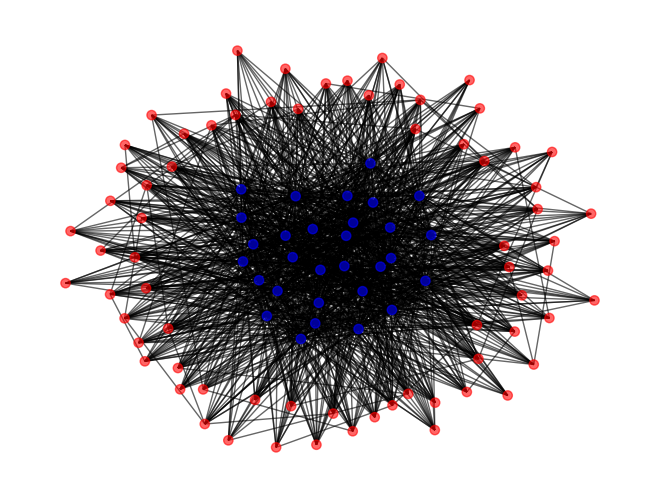

In [29]:
nx.draw_kamada_kawai(G,node_size=45,linewidths=1,alpha=0.6,node_color=node_labels2)

In [30]:
Rs[2]['Theta']

array([[0.01697723, 0.51666667],
       [0.51666667, 0.49885057]])

In [16]:
fits = {}
ilouvain_aris = []
sa_aris = []
stoc_aris = []

for sed in tqdm(range(500)):
    random.seed(sed)
    np.random.seed(sed)
    size_comm = [30,70]
    probs = [[0.5, 0.5],[0.5,0.02]]
    G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)
    A=nx.adjacency_matrix(G).todense()

    Xg=np.zeros((100,2))
    Xg[:30,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=30)
    Xg[30:,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=70)

    Xg=pd.DataFrame(Xg)

    Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
    Xc.loc[:29,'attr_cat1'] = random.choices([1,2,3], k=30, weights=[0.8,0.15,0.05])
    Xc.loc[30:,'attr_cat1'] = random.choices([1,2,3], k=70, weights=[0.15,0.8,0.05])

    Xc.loc[:29,'attr_cat2'] = random.choices([1,2,3,4], k=30, weights=[0.7,0.15,0.05,0.1])
    Xc.loc[30:,'attr_cat2'] = random.choices([1,2,3,4], k=70, weights=[0.15,0.7,0.05,0.1])

    Ks = [2,3,4]
    Rs = {}

    for K in Ks:
        fit = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
        Rs[K] = fit
    bestK = np.array([Rs[K]['vICL'] for K in Ks]).argmax() + 2
    fits[sed] = Rs[bestK]

    # ILOUVAIN
    attributes = {}
    for node in G.nodes():
        attributes[node] = {
            0: float(Xg.iloc[node, 0]),     # continuous
            1: float(Xg.iloc[node, 1]),     # continuous
            2: str(Xc.iloc[node, 0]),       # categorical
            3: str(Xc.iloc[node, 1]),       # categorical
        }

    attr_types = {0: 'continuous', 1: 'continuous',
                2: 'categorical', 3: 'categorical'}

    ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
    partition_ilouv = ml.findPartition()
    ilouvain_aris.append(ARI(list(partition_ilouv.values()), labels))

    # SA
    result_sa = sa_cluster(G, k=bestK, Xg=Xg, Xc=Xc, n_bins=10, 
                        l=20, c=0.15, sigma=0.5, verbose=False)
    sa_aris.append(adjusted_rand_score(labels, result_sa['labels']))

    # STOC
    result_stoc = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

    stoc_aris.append(ARI(labels, result_stoc['labels']))

    with open('coreperiphery_fits.pkl', 'wb') as f:
        pickle.dump(fits, f)

    with open('coreperiphery_ilouv_aris.pkl', 'wb') as f:
        pickle.dump(ilouvain_aris, f)

    with open('coreperiphery_sa_aris.pkl', 'wb') as f:
        pickle.dump(sa_aris, f)

    with open('coreperiphery_stoc_aris.pkl', 'wb') as f:
        pickle.dump(stoc_aris, f)

  0%|          | 0/500 [00:00<?, ?it/s]

/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:86: RuntimeWarning: invalid value encountered in matmul
  qf = float((diff.T @ Sinv @ diff)[0, 0])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:176: RuntimeWarning: invalid value encountered in scalar multiply
  term_g += r[i, k] * log_mvnorm(Xg[i, :], mu_list[k], Sigma_list[k])


In [57]:
size_comm = [30,70]

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

theta_true = [[0.5, 0.5],[0.5,0.02]]
means_true = [[0.5, 0.5],[2.5, 2.5]]
sigmas_true = [[[0.08, 0.001], [0.001, 0.08]], [[0.07, 0.002], [0.002, 0.07]]]
phi1_true = [[0.8,0.15,0.05],[0.15,0.8,0.05]]
phi2_true =  [[0.7,0.15,0.05,0.1],[0.15,0.7,0.05,0.1]]

In [58]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    return col_ind

def mse(true, est):
    return np.mean((np.array(true) - np.array(est))**2)

In [66]:
with open('coreperiphery_fits.pkl', 'rb') as f:
   fits = pickle.load(f)

K = 2
results = {
    'ari': [],
    'theta': [],
    **{f'mu_{k}': [] for k in range(K)},
    **{f'sigma_{k}': [] for k in range(K)},
    'phi1': [],
    'phi2': [],
}

for sed in range(1):
    fit = fits[sed]
    if fit['r'].shape[1] == 2 and all(p.shape[1] == t for p, t in zip(fit['phi_list'], [3,4])):
        pred = np.argmax(fit['r'], axis=1)
        perm = match_labels(np.array(labels), pred, K)
        
        Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
        mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
        Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
        phi_aligned = [phi[perm, :] for phi in fit['phi_list']]
        
        results['ari'].append(ARI(labels, pred))
        results['theta'].append(mse(theta_true, Theta_aligned))
        results['phi1'].append(mse(phi1_true, phi_aligned[0]))
        results['phi2'].append(mse(phi2_true, phi_aligned[1]))
        
        for k in range(K):
            results[f'mu_{k}'].append(mse(means_true[k], mu_aligned[k]))
            results[f'sigma_{k}'].append(mse(sigmas_true[k], Sigma_aligned[k]))

In [67]:
results

{'ari': [1.0],
 'theta': [0.00010947936800704885],
 'mu_0': [0.0004716717795984895],
 'mu_1': [0.0010583243708293514],
 'sigma_0': [0.00014528238801916348],
 'sigma_1': [1.0308028712838666e-05],
 'phi1': [0.000767195767195767],
 'phi2': [0.0017063492063492068]}

In [59]:
with open('coreperiphery_fits.pkl', 'rb') as f:
   fits = pickle.load(f)

In [60]:
pd.Series([fits[i]['r'].shape[1] for i in fits.keys()]).value_counts()

2    490
3      6
4      4
Name: count, dtype: int64

In [ ]:
sbm_aris = []
for sed in range(500):
    fit = fits[sed]
    pred = np.argmax(fit['r'], axis=1)
    
    sbm_aris.append(ARI(labels, pred))
sbm_aris = np.array(sbm_aris)

In [ ]:
sbm_aris.std()

0.044766620766636026

In [ ]:
results

{'ari': [1.0],
 'theta': [3.5729779258642216e-06],
 'mu_0': [0.00042894893000574056],
 'mu_1': [0.001148103506663117],
 'sigma_0': [1.1121875143560203e-05],
 'sigma_1': [1.1535386881780182e-05],
 'phi1': [0.004333333333333336],
 'phi2': [0.0018999999999999974]}

In [ ]:
summary = pd.DataFrame({key: {'mean': np.mean(vals), 'std': np.std(vals)} 
                         for key, vals in results.items()}).T
print(summary.round(5))

            mean      std
ari      1.00000  0.00000
theta    0.00002  0.00003
mu_0     0.00157  0.00163
mu_1     0.00141  0.00137
sigma_0  0.00018  0.00014
sigma_1  0.00014  0.00011
phi1     0.00220  0.00194
phi2     0.00232  0.00150


In [ ]:
with open('bipartita_ilouv_aris.pkl', 'rb') as f:
   ilouvain_aris = pickle.load(f)

with open('bipartita_sa_aris.pkl', 'rb') as f:
   sa_aris = pickle.load(f)

with open('bipartita_stoc_aris.pkl', 'rb') as f:
   stoc_aris = pickle.load(f)

In [ ]:
vals = ilouvain_aris
print(f"${np.mean(vals).round(5)} \pm {np.std(vals).round(5)}$")

$-0.01319 \pm 0.00232$


In [ ]:
vals = sa_aris
print(f"${np.mean(vals).round(5)} \pm {np.std(vals).round(5)}$")

$0.04692 \pm 0.10422$


In [ ]:
vals = stoc_aris
print(f"${np.mean(vals).round(5)} \pm {np.std(vals).round(5)}$")

$0.00041 \pm 0.00045$


In [ ]:
fit = fits[0]
pred = np.argmax(fit['r'], axis=1)
perm = match_labels(np.array(labels), pred, K)

Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
phi_aligned = [phi[perm, :] for phi in fit['phi_list']]

In [ ]:
theta_true

[[0.01, 0.1], [0.1, 0.01]]

In [ ]:
Theta_aligned

array([[0.01306122, 0.1012    ],
       [0.1012    , 0.01142857]])

# Terzo scenario

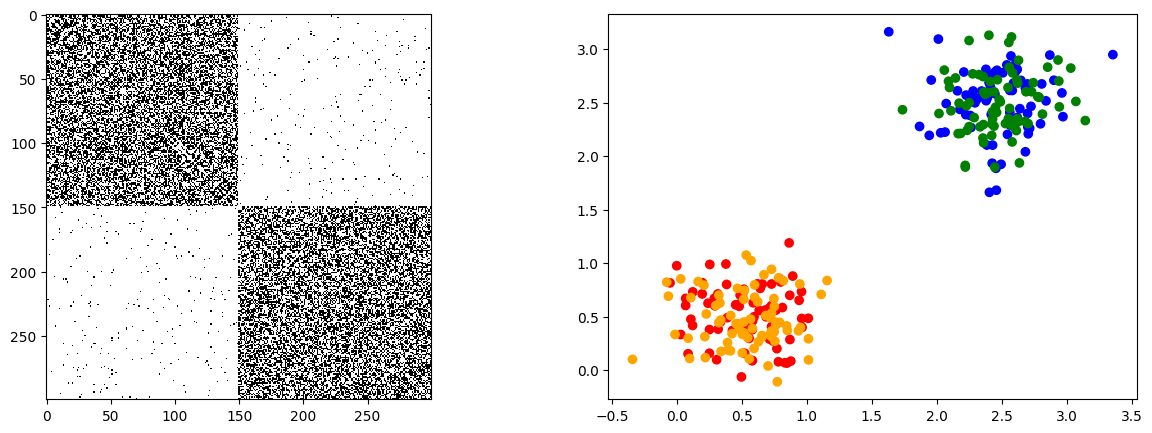

In [16]:
random.seed(42)
size_comm = [150,150]
N = sum(size_comm)
probs = [[0.5, 0.01],[0.01,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((N,2))
Xg[:75,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=75)
Xg[75:225,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=150)
Xg[225:,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=75)

Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()

size_comm2 = [75,75,75,75]
labels = []
for n,i in enumerate(size_comm2):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

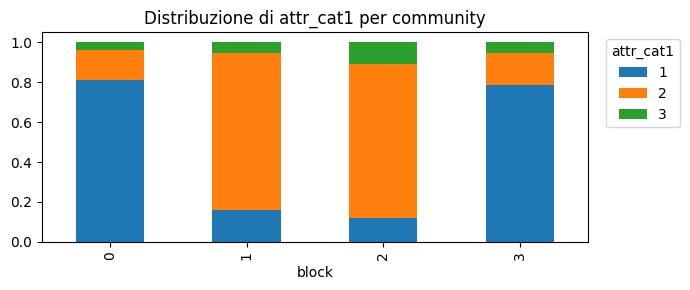

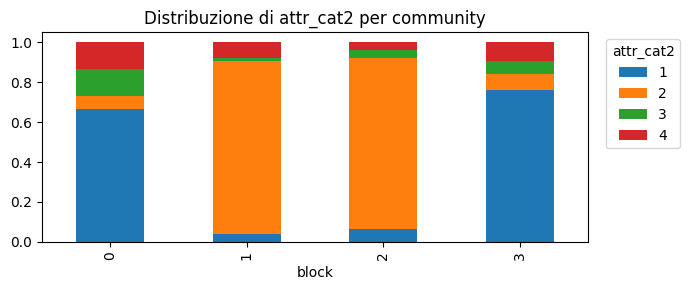

In [23]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:74,'attr_cat1'] = random.choices([1,2,3], k=75, weights=[0.8,0.15,0.05])
Xc.loc[75:224,'attr_cat1'] = random.choices([1,2,3], k=150, weights=[0.15,0.8,0.05])
Xc.loc[225:,'attr_cat1'] = random.choices([1,2,3], k=75, weights=[0.8,0.15,0.05])

Xc.loc[:74,'attr_cat2'] = random.choices([1,2,3,4], k=75, weights=[0.8,0.05,0.05,0.1])
Xc.loc[75:224,'attr_cat2'] = random.choices([1,2,3,4], k=150, weights=[0.05,0.8,0.05,0.1])
Xc.loc[225:,'attr_cat2'] = random.choices([1,2,3,4], k=75, weights=[0.8,0.05,0.05,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [24]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW_old
from vem_sbm_new_version_VICL import VEM_SBM as VEM_SBM_NEW_vicl


Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [25]:
[Rs[k]['vICL'] for k in Rs.keys()]

[-18255.959344277642,
 -18287.641203335224,
 -17873.09025776038,
 -17917.005519858187]

In [27]:
pd.DataFrame(Rs[4]['r']).round(3)

,0,1,2,3
0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0
...,...,...,...,...
295,0.0,0.0,0.0,1.0
296,0.0,0.0,0.0,1.0
297,0.0,0.0,0.0,1.0
298,0.0,0.0,0.0,1.0


In [2]:
with open('struttureDiscordanti_fits.pkl', 'rb') as f:
    fits = pickle.load(f)

In [5]:
with open('struttureDiscordanti_ilouv_aris.pkl', 'rb') as f:
    ilouvain_aris = pickle.load(f)

In [6]:
with open('struttureDiscordanti_sa_aris.pkl', 'rb') as f:
    sa_aris = pickle.load(f)

In [7]:
with open('struttureDiscordanti_stoc_aris.pkl', 'rb') as f:
    stoc_aris = pickle.load(f)

In [ ]:
fits.keys() # 241

dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219,

In [10]:
size_comm2 = [75,75,75,75]
labels = []
for n,i in enumerate(size_comm2):
    labels += [n]*i

In [11]:
# fits = {}
# ilouvain_aris = []
# sa_aris = []
# stoc_aris = []

for sed in tqdm(range(242,500)):
    random.seed(sed)
    np.random.seed(sed)
    size_comm = [150,150]
    N = sum(size_comm)
    probs = [[0.5, 0.01],[0.01,0.5]]
    G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

    Xg=np.zeros((N,2))
    Xg[:75,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=75)
    Xg[75:225,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=150)
    Xg[225:,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=75)

    Xg=pd.DataFrame(Xg)
    A=nx.adjacency_matrix(G).todense()

    Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
    Xc.loc[:74,'attr_cat1'] = random.choices([1,2,3], k=75, weights=[0.8,0.15,0.05])
    Xc.loc[75:224,'attr_cat1'] = random.choices([1,2,3], k=150, weights=[0.15,0.8,0.05])
    Xc.loc[225:,'attr_cat1'] = random.choices([1,2,3], k=75, weights=[0.8,0.15,0.05])

    Xc.loc[:74,'attr_cat2'] = random.choices([1,2,3,4], k=75, weights=[0.8,0.05,0.05,0.1])
    Xc.loc[75:224,'attr_cat2'] = random.choices([1,2,3,4], k=150, weights=[0.05,0.8,0.05,0.1])
    Xc.loc[225:,'attr_cat2'] = random.choices([1,2,3,4], k=75, weights=[0.8,0.05,0.05,0.1])

    Ks = [2,3,4,5]
    Rs = {}

    for K in Ks:
        fit = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
        Rs[K] = fit
    bestK = np.array([Rs[K]['vICL'] for K in Ks]).argmax() + 2
    fits[sed] = Rs[bestK]

    # ILOUVAIN
    attributes = {}
    for node in G.nodes():
        attributes[node] = {
            0: float(Xg.iloc[node, 0]),     # continuous
            1: float(Xg.iloc[node, 1]),     # continuous
            2: str(Xc.iloc[node, 0]),       # categorical
            3: str(Xc.iloc[node, 1]),       # categorical
        }

    attr_types = {0: 'continuous', 1: 'continuous',
                2: 'categorical', 3: 'categorical'}

    ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
    partition_ilouv = ml.findPartition()
    ilouvain_aris.append(ARI(list(partition_ilouv.values()), labels))

    # SA
    result_sa = sa_cluster(G, k=bestK, Xg=Xg, Xc=Xc, n_bins=10, 
                        l=20, c=0.15, sigma=0.5, verbose=False)
    sa_aris.append(adjusted_rand_score(labels, result_sa['labels']))

    # STOC
    result_stoc = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

    stoc_aris.append(ARI(labels, result_stoc['labels']))

    with open('struttureDiscordanti_fits.pkl', 'wb') as f:
        pickle.dump(fits, f)

    with open('struttureDiscordanti_ilouv_aris.pkl', 'wb') as f:
        pickle.dump(ilouvain_aris, f)

    with open('struttureDiscordanti_sa_aris.pkl', 'wb') as f:
        pickle.dump(sa_aris, f)

    with open('struttureDiscordanti_stoc_aris.pkl', 'wb') as f:
        pickle.dump(stoc_aris, f)

  0%|          | 0/258 [00:00<?, ?it/s]

/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:176: RuntimeWarning: invalid value encountered in scalar multiply
  term_g += r[i, k] * log_mvnorm(Xg[i, :], mu_list[k], Sigma_list[k])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:86: RuntimeWarning: invalid value encountered in matmul
  qf = float((diff.T @ Sinv @ diff)[0, 0])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:86: RuntimeWarning: invalid value encountered in matmul
  qf = float((diff.T @ Sinv @ diff)[0, 0])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:176: RuntimeWarning: invalid value encountered in scalar multiply
  term_g += r[i, k] * log_mvnorm(Xg[i, :], mu_list[k], Sigma_list[k])
/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/vem_sbm_new_version_VICL.py:169: RuntimeWarning: divide by zero enco

In [117]:
Rs[2]['phi_list']

[array([[0.8       , 0.13333333, 0.06666667],
        [0.1       , 0.85      , 0.05      ]]),
 array([[0.66666667, 0.15      , 0.08333333, 0.1       ],
        [0.13333333, 0.66666667, 0.05      , 0.15      ]])]

In [57]:
Rs[4]['Theta']

array([[0.51099099, 0.05742222, 0.05333333, 0.496     ],
       [0.05742222, 0.51279279, 0.50062222, 0.05066667],
       [0.05333333, 0.50062222, 0.48288288, 0.05262222],
       [0.496     , 0.05066667, 0.05262222, 0.49837838]])

In [60]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[4]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

In [ ]:
Rs[3]['Theta']

array([[0.50122449, 0.1016    , 0.2128    ],
       [0.1016    , 0.50530612, 0.0536    ],
       [0.2128    , 0.0536    , 0.5877551 ]])

In [ ]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    """Find the permutation of pred labels that best matches true labels."""
    # Build cost matrix: -overlap between each (true k, pred l) pair
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[k] = which predicted label corresponds to true label k
    return col_ind

perm = match_labels(np.array(labels), pred_labels_sbm, 3)
# perm[k] = estimated label that corresponds to true block k

# Reorder Theta to match true label order
Theta_est = Rs[3]['Theta']
Theta_aligned = Theta_est[np.ix_(perm, perm)]
print('True:\n', np.array(probs))
print('Estimated (aligned):\n', np.round(Theta_aligned, 3))

True:
 [[0.6  0.2  0.05]
 [0.2  0.5  0.1 ]
 [0.05 0.1  0.5 ]]
Estimated (aligned):
 [[0.588 0.213 0.054]
 [0.213 0.501 0.102]
 [0.054 0.102 0.505]]


### ILouvain

In [ ]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [ ]:
ARI(list(partition_ilouv.values()), labels)

-0.01320487273773085

### SA cluster third

In [ ]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0035


### STOC cluster third

In [ ]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.3066
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 100 clusters
k=99  ARI=0.0004
